# TreeVibes — Windows CUDA training and Colab recovery

Select your brother's existing **Windows Python 3.12 kernel** and **Run All**. No reboot or WSL is required. Remaining neural fits and distillation use **PyTorch CUDA** on the RTX 5060 Ti; completed TensorFlow results are reused. Trusted Keras weights are converted through an audited layer graph, with numerical inference checks before training and before saving the Keras export.

**Framework migration:** committed Keras epochs, history and weights are retained. Adam state resets once when switching to PyTorch; subsequent PyTorch optimizer states resume normally. Dropout/numerical trajectories can differ. Backend fingerprints and `backend.json` identify converted runs. Original models and Drive files remain untouched.

**CPU stages:** feature preparation, weight serialization, TFLite PTQ/conversion and the existing short TensorFlow QAT export stage still run on CPU. The full supervised/student search uses CUDA. First-time dependency installation is reused from the standard Windows notebook. Default storage remains `D:/ML/TreeVibesWindows`; keep the PC awake.

The public experiment ZIP downloads once and is safely extracted before recovery. Share the ZIP as **Anyone with the link → Viewer**; the notebook does not require a browser login. After download succeeds, access can be restricted again. Completed local downloads and experiments are reused.

## 1. Settings

Defaults run the full study. `MODE="screening"` provides a shorter run. Keep final-test evaluation disabled while searching; enable it here when ready to lock finalists. Remote inputs stay **30 × 13 MFCCs**. Larger local inputs are separate experiments.

In [1]:
from pathlib import Path
import os, sys

# Full runs all 131 recipes; screening runs a short search plus distillation.
SMOKE = os.environ.get("TREEVIBES_SMOKE", "0") == "1"
MODE = "smoke" if SMOKE else "full"
EPOCHS = 1 if SMOKE else 60
EXPORT_TOP_N = 1 if SMOKE else 3
QAT_EPOCHS = 1 if SMOKE else 3
RUN_FINAL_TEST = False  # Enable only when ready to lock finalists and release test results.
GROUPS_CSV = None  # Optional tree/session metadata CSV: filepath,group.
DATASET_ROOT = None  # None automatically reuses/downloads the Kaggle dataset.
WORK = Path(os.environ.get("TREEVIBES_WINDOWS_WORK", "D:/ML/TreeVibesWindows")).resolve()
OUTPUT = WORK / "experiments"
SOURCE_FOLDER = None  # Optional existing complete downloaded experiment folder.
DRIVE_ZIP_ID = "1MsF2OEAHqL4uOhhZ8nJEiFCEMVoEn1ZT"


## 2. Load the embedded project

The notebook carries all source files and configurations.

In [2]:
#@title Load the embedded project
from pathlib import Path
import base64, io, os, sys, zipfile
payload = base64.b64decode('...')
ROOT = WORK / "project"
ROOT.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(io.BytesIO(payload)) as archive:
    for member in archive.infolist():
        if not (ROOT/member.filename).resolve().is_relative_to(ROOT.resolve()):
            raise ValueError("Unsafe embedded archive path")
    archive.extractall(ROOT)
sys.path.insert(0, str(ROOT))
for name in list(sys.modules):
    if name == "treevibes" or name.startswith("treevibes.") or name == "scripts" or name.startswith("scripts."):
        del sys.modules[name]
os.chdir(ROOT)
print("Embedded project ready.")


Embedded project ready.


## 3. Download and extract the experiment ZIP

Downloads the shared ZIP without login, validates extraction paths and CRCs, and locates the experiments folder automatically. Completed downloads/extractions are reused. Original ZIP contents remain separate from the working experiments. Keep the PC awake; do not delete the Python/Jupyter environment.

In [3]:
from scripts.zip_recovery import download_zip

if SMOKE:
    SOURCE = None
elif SOURCE_FOLDER:
    SOURCE = Path(SOURCE_FOLDER).expanduser().resolve()
else:
    SOURCE = download_zip(WORK, DRIVE_ZIP_ID)
if SOURCE is not None and not (SOURCE / "notebook_settings.json").is_file():
    raise FileNotFoundError("ZIP must contain the complete TreeVibesExperiments folder.")
print("Original snapshot:", SOURCE)


Downloaded 0.06 GB
Downloaded 0.12 GB
Extracting experiment ZIP (0.17 GB).
Original snapshot: D:\ML\TreeVibesWindows\zip_snapshot\TreeVibesExperiments


## 4. Create isolated training environments

First setup may download several GB of packages. Subsequent runs reuse the environments. Keras seed compatibility is repaired, and actual CPU/GPU convolution gradients are checked.

In [4]:
import json, subprocess
from treevibes.runtime import check_frameworks, worker_environment
from scripts.windows_support import prepare_windows_workers, run_logged

os.environ["KAGGLEHUB_CACHE"] = str(WORK / "downloads")
# A previous CPU-only notebook may have hidden the GPU in this kernel's environment.
os.environ.pop("CUDA_VISIBLE_DEVICES", None)
if SMOKE:
    python = os.environ.get("TREEVIBES_WORKER_PYTHON", sys.executable)
    WORKERS = {"tensorflow": python, "pytorch": python}
else:
    WORKERS = prepare_windows_workers(ROOT, WORK)
check_frameworks(WORKERS, WORK / "preflight", require_gpu=False)
if not SMOKE:
    probe = """import json, torch
assert torch.cuda.is_available(), 'RTX GPU is unavailable; see pytorch_gpu.log.'
x = torch.ones(2, 1, 30, 13, device='cuda', requires_grad=True)
w = torch.ones(4, 1, 3, 3, device='cuda', requires_grad=True)
y = torch.nn.functional.conv2d(x, w)
y.sum().backward()
assert all(t.grad is not None and bool(torch.isfinite(t.grad).all()) for t in [x,w])
print(json.dumps({'torch':torch.__version__,'cuda':torch.version.cuda,'gpu':torch.cuda.get_device_name(0)}))
"""
    run_logged([WORKERS["pytorch"], "-c", probe], WORK / "pytorch_gpu.log",
               env=worker_environment(ROOT), stream=True)
print("Workers ready: TensorFlow CPU; PyTorch", "CPU check" if SMOKE else "RTX GPU")


tensorflow {"version": "2.16.2", "device": "/job:localhost/replica:0/task:0/device:CPU:0"}
pytorch {"version": "2.7.1+cu128", "device": "cpu"}
{"torch": "2.7.1+cu128", "cuda": "12.8", "gpu": "NVIDIA GeForce RTX 5060 Ti"}
Workers ready: TensorFlow CPU; PyTorch RTX GPU


## 5. Prepare data, train, distill and quantize

Byte-identical recordings with opposing labels are excluded and audited; source WAV files stay unchanged. Preprocessing reports progress. The workflow trains supervised recipes first, selects a compatible teacher using validation data, runs distillation, then compares float, full INT8 PTQ and QAT exports. Each fit/conversion runs in a fresh process. Failures are recorded and compatible recipes continue. Checkpoints, the Excel tracker and the campaign journal are saved incrementally.

Recovery prints verified imported run/cache counts first. Recipes still appear from 1/131, but verified completed models print `Reusing verified completed run.` Intact interrupted epochs are restored. The raw Kaggle archive is downloaded only when an unfinished feature cache needs audio. New hardware/framework versions are recorded in new attempt provenance; continuation is not promised to be bitwise identical.

Unfinished neural fits now run on CUDA, including converted teachers for distillation. CUDA is required for real training; CPU fallback is allowed only in explicit synthetic verification.

In [5]:
SETTINGS = dict(mode=MODE, output=str(OUTPUT), epochs=EPOCHS,
                export_top_n=EXPORT_TOP_N, qat_epochs=QAT_EPOCHS,
                final_test=RUN_FINAL_TEST, groups_csv=str(GROUPS_CSV) if GROUPS_CSV else None,
                dataset_root=str(DATASET_ROOT) if DATASET_ROOT else None,
                reference_python=WORKERS["pytorch"])
settings_path = WORK / "windows_notebook_settings.json"
settings_path.write_text(json.dumps(SETTINGS, indent=2))

if not SMOKE:
    migration = (
        "import json; from pathlib import Path; "
        "from scripts.windows_support import import_experiments, seed_campaign; "
        f"import_experiments(Path({str(SOURCE)!r}), Path({str(OUTPUT)!r})); "
        f"settings=json.loads(Path({str(settings_path)!r}).read_text()); "
        f"print(json.dumps(seed_campaign(settings, Path({str(ROOT)!r})), indent=2))"
    )
    run_logged([WORKERS["tensorflow"], "-c", migration], WORK / "windows_resume.log",
               env=worker_environment(ROOT), stream=True, cwd=ROOT)
    # Preserve the original downloaded settings separately from current controller settings.
    (OUTPUT / "notebook_settings.json").write_text(json.dumps(SETTINGS, indent=2))

environment = worker_environment(ROOT)
environment["TREEVIBES_TF_PYTHON"] = WORKERS["tensorflow"]
if SMOKE:
    environment["TREEVIBES_ALLOW_CPU_TEST"] = "1"
# Working tracking database and backups stay on this PC.
environment["TREEVIBES_TRACKING_DIR"] = str(ROOT / "tracking")
run_logged([WORKERS["tensorflow"], "-m", "scripts.gpu_campaign", "--settings", str(settings_path)],
           OUTPUT / "campaign.log", env=environment, stream=True, cwd=ROOT)


{
  "destination": "D:\\ML\\TreeVibesWindows\\experiments",
  "invalid_completed_runs": [],
  "original_output": "/content/drive/MyDrive/TreeVibesExperiments",
  "preserved_tracking_backups": [
    "imported_tracking\\tracking_backup-mlflow-3.14.0.db",
    "imported_tracking\\tracking_backup.db"
  ],
  "source": "D:\\ML\\TreeVibesWindows\\zip_snapshot\\TreeVibesExperiments",
  "verified_completed_runs": 40,
  "compatible_completed_runs": 39,
  "verified_caches": 6,
  "campaign_id": "be6e413bf2c565da"
}
Reusing the verified feature cache; no raw download required.
[1/131] forest_coefficient
  validation F1=0.8631
[2/131] forest_none
  validation F1=0.8631
[3/131] histogram_coefficient
  validation F1=0.8619
[4/131] histogram_none
  validation F1=0.8619
[5/131] logistic_coefficient
  validation F1=0.7234
[6/131] logistic_none
  validation F1=0.6744
[7/131] reference_a
TV_PROGRESS reference_a epoch 1/60: validation loss=0.63238
TV_PROGRESS reference_a epoch 5/60: validation loss=0.51315
T

## 6. Results and ESP32 candidates

Validation comparisons and exported model sizes appear below; all runs and failures are in the Excel tracker. The ESP32-WROOM-32 budget is **2 MB total flash and approximately 0.5 MB RAM**. Board inference, full application memory, latency and waveform-to-MFCC parity still require hardware. Without source metadata, file-level splits do not prove performance on unseen trees.

Status: completed
Training recipes: 131 / 131
Exports: 27 | Recorded failures: 0
Excel tracker: D:\ML\TreeVibesWindows\experiments\leaderboard.xlsx
ESP32 model bundles: D:\ML\TreeVibesWindows\experiments\esp32_candidates.zip
Progress and complete logs: D:\ML\TreeVibesWindows\experiments


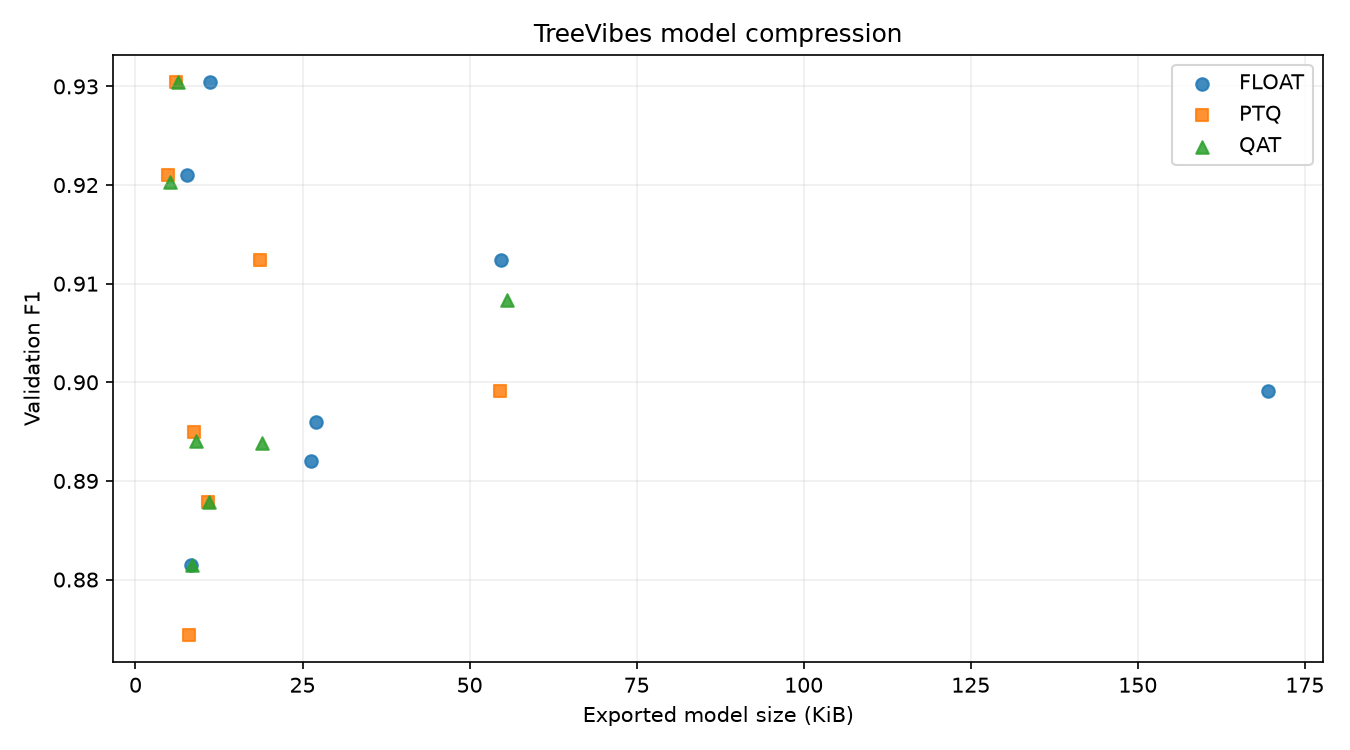

Recipe,F1,Parameters
temporal_ablation_01,0.930,2241
temporal_ablation_05,0.930,2241
temporal_w64,0.926,27393
temporal_w32,0.926,7553
temporal_ablation_03,0.925,2241
temporal_ablation_02,0.924,2241
tiny_temporal_w12,0.921,1393
temporal_w16,0.920,2241
temporal_60x20,0.920,905
cnn_w64,0.920,369921


In [6]:
from IPython.display import display, HTML, Image
SUMMARY = json.loads((OUTPUT / "campaign_summary.json").read_text())
print("Status:", SUMMARY["state"])
print("Training recipes:", SUMMARY["completed_runs"], "/", SUMMARY["planned_runs"])
print("Exports:", len(SUMMARY["exports"]), "| Recorded failures:", len(SUMMARY["failures"]))
print("Excel tracker:", OUTPUT / "leaderboard.xlsx")
print("ESP32 model bundles:", OUTPUT / "esp32_candidates.zip")
print("Progress and complete logs:", OUTPUT)
if SUMMARY.get("report_error"):
    print("Results are saved; report needs retry:", SUMMARY["report_error"])
else:
    if (OUTPUT / "comparison.png").exists():
        display(Image(filename=str(OUTPUT / "comparison.png")))
    if (OUTPUT / "campaign_report.html").exists():
        report = (OUTPUT / "campaign_report.html").read_text()
        # The chart is displayed separately so relative HTML image paths are unnecessary.
        display(HTML(report.replace('<img src="comparison.png" alt="Validation F1 versus exported model size">', '')))
